## Create Toy Dataset


In [22]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

X, y = make_blobs(n_samples=1000, centers=2, n_features=2, random_state=42, cluster_std=3.0)


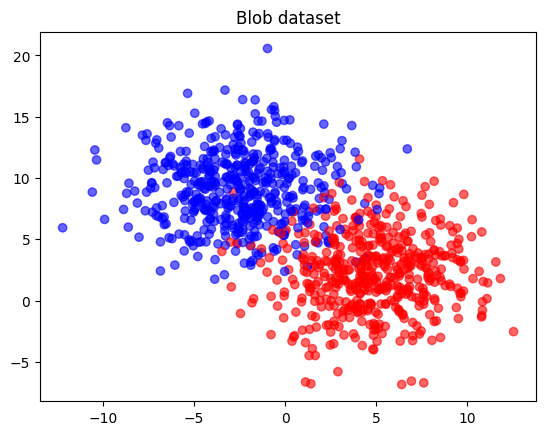

In [36]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', alpha=0.6)
plt.title("Blob dataset")
plt.show()

## Split to train and test sets

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Train the models

In [25]:
from logRegL1 import LogisticRegressionL1
from sklearn.metrics import precision_score, recall_score, f1_score

model = LogisticRegressionL1(lr=0.1, lambda_reg=5.0, n_iter=2000)
model.fit(X_train, y_train)

sklearn_model = LogisticRegression(penalty='l1', C=0.2, solver='liblinear', random_state=42)
sklearn_model.fit(X_train, y_train)

Iteration 0 | Loss: 0.3531
Early stopping at iteration 68


LogisticRegression(C=0.2, penalty='l1', random_state=42, solver='liblinear')

## Test the models and compare

In [34]:
y_pred = model.predict(X_test)
y_pred_sk = sklearn_model.predict(X_test)

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Custom model Precision: {precision:.4f}")
print(f"Custom model Recall: {recall:.4f}")
print(f"Custom model F1-Score: {f1:.4f}\n")

precision = precision_score(y_test, y_pred_sk)
recall = recall_score(y_test, y_pred_sk)
f1 = f1_score(y_test, y_pred_sk)

print(f"SK model Precision: {precision:.4f}")
print(f"SK model Recall: {recall:.4f}")
print(f"SK model F1-Score: {f1:.4f}")


Custom model Precision: 0.9677
Custom model Recall: 0.9278
Custom model F1-Score: 0.9474

SK model Precision: 0.9681
SK model Recall: 0.9381
SK model F1-Score: 0.9529


Both custom and scikit-learn models with L1 regularization show a very similar performance. The scikit-learn model is sligthly better since it is highly optimized and solved with efficient solvers.

## Plot decision boundary for the test set in the implemented model

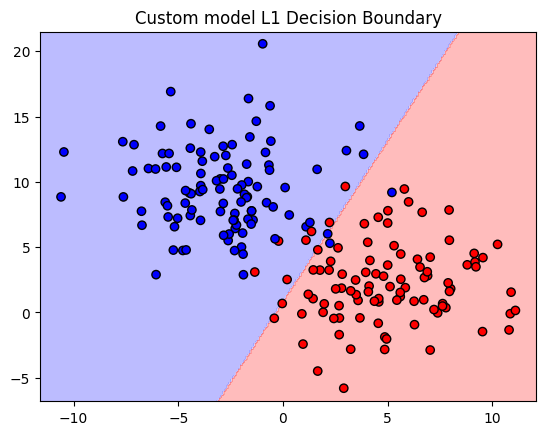

In [45]:
def plot_decision_boundary(X, y, model, model_type="Custom model"):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                         np.arange(y_min, y_max, 0.1))

    grid_points = np.c_[xx.ravel(), yy.ravel()]

    Z = np.array(model.predict(grid_points))
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap='bwr')
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='bwr')
    plt.title(f"{model_type} L1 Decision Boundary")
    plt.show()

plot_decision_boundary(X_test, y_test, model)

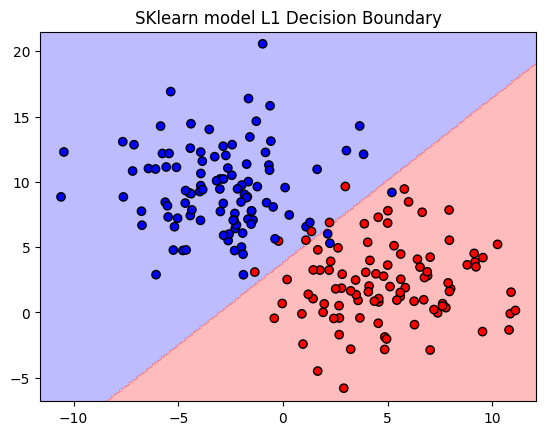

In [46]:
plot_decision_boundary(X_test, y_test, sklearn_model, model_type="SKlearn model")